# Advanced Machine Learning 2026/2027
## Project: Modeling Recovery after Lower-Limb Musculoskeletal Injury
### M5 — Hidden Markov Models

**Group:** 14

| Number | Name |
|---|---|
| fc68043 | David Belykh |
| fc68080 | Matilde Quitério |
| fc68091 | Ramyad Raadi |

### Statement on the use of generative AI
The generative AI tool **Claude (Anthropic)** was used in this milestone to support code generation, notebook structuring, debugging and the drafting of written explanations. All code was executed by the group, and every modelling decision, numerical result, interpretation and conclusion was reviewed and validated by the group members, who are able to explain and justify the submitted content.

## 0. Setup, Data Loading and the M4 Train/Test Split

Up to M4 every patient-week was treated as an independent observation. In this milestone we model each patient as a **sequence of 14 weekly observations** generated by a hidden recovery state that evolves according to a first-order Markov chain.

As required, we reuse **exactly the patient-level 70/30 split from M4** (same `RANDOM_STATE = 42`, same `np.random.default_rng(...).permutation` of the sorted patient IDs): $2{,}100$ training patients and $900$ test patients, with all 14 weeks of each patient kept in the same set.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse
from scipy.stats import multivariate_normal, skew, kurtosis
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import hmmlearn
from hmmlearn.hmm import GaussianHMM

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
STATE_ORDER = ["Limited", "Recovering", "Functional"]
STATE_RANK = {s: i for i, s in enumerate(STATE_ORDER)}
STATE_COLORS = {"Limited": "#E74C3C", "Recovering": "#F39C12", "Functional": "#27AE60"}
OBS_ALL = ["mobility", "pain", "fatigue", "functional_confidence", "activity", "adherence"]


def find_file(filename, search_paths=(".", "..", "/mnt/data", "dataset", "../dataset")):
    for base in search_paths:
        if not os.path.exists(base):
            continue
        for root, _, files in os.walk(base):
            if filename in files:
                return os.path.join(root, filename)
    raise FileNotFoundError(f"Could not find {filename}.")


rehab = pd.read_csv(find_file("rehabilitation.csv"))
rehab = rehab.sort_values(["patient_id", "week"]).reset_index(drop=True)

# Reproduce the M4 patient-level split exactly
rng = np.random.default_rng(RANDOM_STATE)
unique_pids = np.sort(rehab["patient_id"].unique())
shuffled_pids = rng.permutation(unique_pids)
n_train_patients = int(round(0.70 * len(unique_pids)))
train_pids = np.sort(shuffled_pids[:n_train_patients])
test_pids = np.sort(shuffled_pids[n_train_patients:])
assert len(set(train_pids) & set(test_pids)) == 0

train_df = rehab[rehab["patient_id"].isin(train_pids)].reset_index(drop=True)
test_df = rehab[rehab["patient_id"].isin(test_pids)].reset_index(drop=True)

print(f"hmmlearn version: {hmmlearn.__version__}")
print(f"Train: {len(train_pids):,} patients ({len(train_df):,} patient-weeks) | "
      f"Test: {len(test_pids):,} patients ({len(test_df):,} patient-weeks) | Overlap: 0")
print(f"Weeks per patient: {sorted(rehab.groupby('patient_id').size().unique())} (weeks {rehab.week.min()}-{rehab.week.max()})")

hmmlearn version: 0.3.3
Train: 2,100 patients (29,400 patient-weeks) | Test: 900 patients (12,600 patient-weeks) | Overlap: 0
Weeks per patient: [np.int64(14)] (weeks 0-13)


---
## Task 1: Model Setup

### 1.1 Choosing two observable rehabilitation variables

The HMM itself never sees `state`. However, to justify *which* two measurements are most informative about recovery, we summarise how each candidate measurement behaves across the recovery states **on the training patients only** (this extends the M0 Task 4 analysis). For each variable we report the state means, the pooled within-state standard deviation and a simple **separation ratio** $=\dfrac{\text{Var}_{\text{between states}}(\mu_s)}{\text{mean}_s\,\text{Var}_{\text{within}}(x\mid s)}$: the larger the ratio, the better the variable distinguishes the states relative to its noise.

,Variable,Mean | Limited,Mean | Recovering,Mean | Functional,Pooled within-state SD,Separation ratio
0,functional_confidence,37.7388,54.5218,71.0469,10.0566,1.8283
1,mobility,40.4665,56.1291,71.4980,9.5610,1.7558
2,activity,24.7389,42.3435,59.0323,11.9058,1.3831
3,pain,7.1144,5.4937,3.9233,1.1942,1.1902
4,fatigue,6.5132,5.3583,4.1665,1.1778,0.6617
5,adherence,58.7782,61.7524,63.1934,15.4446,0.0142


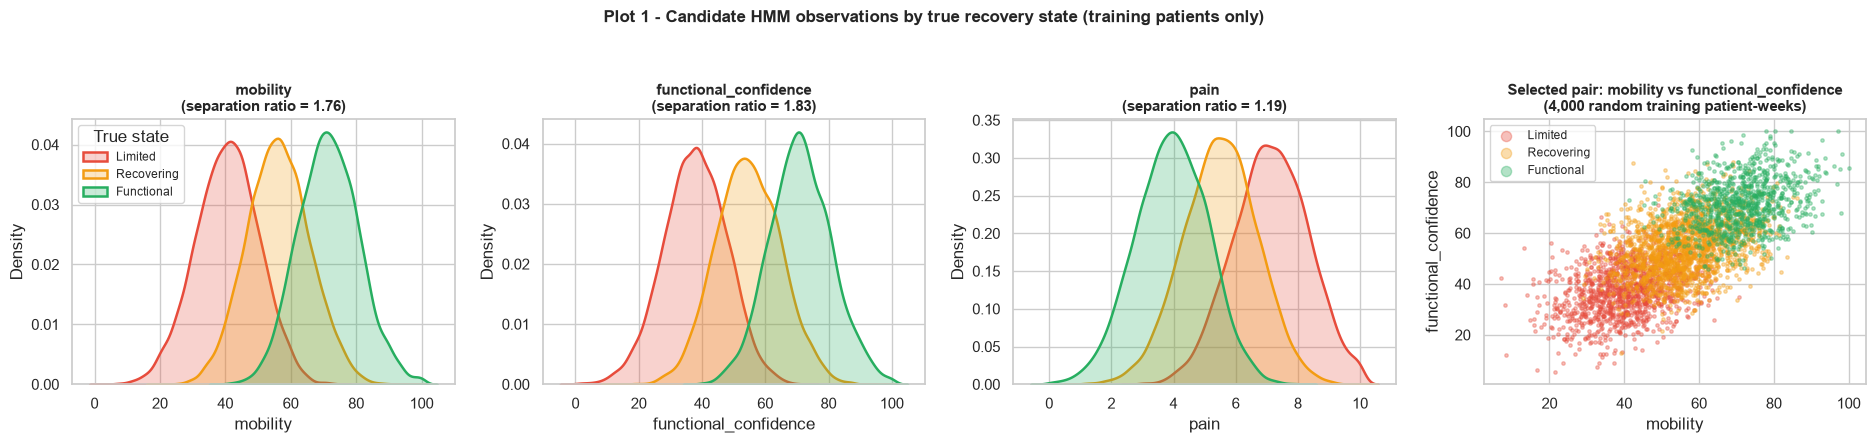

In [2]:
sep_rows = []
for v in OBS_ALL:
    g = train_df.groupby("state")[v]
    means = g.mean().reindex(STATE_ORDER)
    within_var = g.var().mean()
    sep_rows.append({
        "Variable": v,
        "Mean | Limited": means["Limited"],
        "Mean | Recovering": means["Recovering"],
        "Mean | Functional": means["Functional"],
        "Pooled within-state SD": np.sqrt(within_var),
        "Separation ratio": means.var(ddof=0) / within_var,
    })
sep_df = pd.DataFrame(sep_rows).sort_values("Separation ratio", ascending=False).reset_index(drop=True)
display(sep_df)

# Plot 1: distributions of the candidate measurements by (true) recovery state, training patients only
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, v in zip(axes[:3], ["mobility", "functional_confidence", "pain"]):
    for s in STATE_ORDER:
        sns.kdeplot(train_df.loc[train_df.state == s, v], ax=ax, fill=True, alpha=0.25,
                    color=STATE_COLORS[s], label=s, linewidth=1.8)
    ratio = sep_df.set_index("Variable").loc[v, "Separation ratio"]
    ax.set_title(f"{v}\n(separation ratio = {ratio:.2f})", fontsize=10.5, fontweight="bold")
    ax.set_xlabel(v)
axes[0].legend(title="True state", fontsize=8.5)

sample = train_df.sample(4000, random_state=RANDOM_STATE)
for s in STATE_ORDER:
    sub = sample[sample.state == s]
    axes[3].scatter(sub["mobility"], sub["functional_confidence"], s=6, alpha=0.35,
                    color=STATE_COLORS[s], label=s)
axes[3].set_xlabel("mobility")
axes[3].set_ylabel("functional_confidence")
axes[3].set_title("Selected pair: mobility vs functional_confidence\n(4,000 random training patient-weeks)",
                  fontsize=10.5, fontweight="bold")
axes[3].legend(markerscale=3, fontsize=8.5)
plt.suptitle("Plot 1 - Candidate HMM observations by true recovery state (training patients only)",
             fontsize=12, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

**Choice: `mobility` and `functional_confidence`.**

* They are the two measurements with the **largest separation ratio** (1.83 for `functional_confidence` and 1.76 for `mobility`), i.e. their state means are far apart relative to their within-state noise. Their means increase monotonically from `Limited` to `Recovering` to `Functional` (about 38 → 55 → 71 and 40 → 56 → 71 on the 0–100 scale), so both track the recovery level directly. `activity` (1.38) and `pain` (1.19) are informative but weaker, `fatigue` is weak (0.66), and `adherence` carries almost no information about the state (0.014).
* They provide **complementary perspectives**: `mobility` is a functional (performance-based) measurement, whereas `functional_confidence` is patient-reported and reflects how confident the patient feels when performing functional tasks.
* Their overall correlation is high (0.72), but most of it is explained by the recovery state itself: **within** a state the correlation is only about 0.26–0.32 (Section 1.2). Given the state, each variable therefore still adds information that the other does not provide.

The true `state` labels are used here only to *describe* the variables (as in the M0 EDA). They are not used anywhere in fitting the HMM.

### 1.2 Choice of emission model

Both selected variables are **continuous** scores on a 0–100 scale. Among the emission models studied in the laboratory (`CategoricalHMM` for discrete symbols, `GaussianHMM`, and `GMMHMM` for mixtures of Gaussians), we check the shape of each variable *within* a recovery state to decide which one is appropriate:

In [3]:
FEATURES = ["mobility", "functional_confidence"]

shape_rows = []
for s in STATE_ORDER:
    sub = train_df.loc[train_df.state == s, FEATURES]
    shape_rows.append({
        "True state": s,
        "n": len(sub),
        "Skewness mobility": skew(sub["mobility"]),
        "Excess kurtosis mobility": kurtosis(sub["mobility"]),
        "Skewness func_conf": skew(sub["functional_confidence"]),
        "Excess kurtosis func_conf": kurtosis(sub["functional_confidence"]),
        "Within-state corr(mob, func_conf)": sub["mobility"].corr(sub["functional_confidence"]),
    })
display(pd.DataFrame(shape_rows))
print(f"Overall (marginal) correlation mobility vs functional_confidence: "
      f"{train_df['mobility'].corr(train_df['functional_confidence']):.4f}")

,True state,n,Skewness mobility,Excess kurtosis mobility,Skewness func_conf,Excess kurtosis func_conf,"Within-state corr(mob, func_conf)"
0,Limited,9517,-0.0792,-0.0653,-0.0983,0.0183,0.3116
1,Recovering,12731,0.0733,-0.0695,0.0485,-0.0767,0.3171
2,Functional,7152,0.0971,-0.0346,0.0876,-0.0564,0.2553


Overall (marginal) correlation mobility vs functional_confidence: 0.7201


**Emission model: `GaussianHMM` with full covariance matrices.**

* Both observations are continuous, so a Gaussian emission model is the natural choice. Within each true state the distributions are close to Gaussian and unimodal (|skewness| ≤ 0.10 and |excess kurtosis| ≤ 0.08 in every state; see also the bell-shaped curves in Plot 1).
* A `CategoricalHMM` would require discretising the scores (e.g. with the M2 bins), which throws away information inside each bin. A `GMMHMM` (a mixture of Gaussians per state) would add many parameters without evidence of multimodality within states.
* We use **`covariance_type="full"`** because the two variables remain correlated within each state (0.26–0.32). A diagonal covariance would ignore this and treat them as two independent pieces of evidence. With two variables, a full covariance costs only 3 parameters per state.

### 1.3 Preprocessing and sequence organisation

* **Standardisation:** a `StandardScaler` is fitted on the **training patients only** and then applied to both sets (no information from test patients is used). This puts both variables on a comparable scale and improves the numerical conditioning of the EM updates; it is an invertible linear transform, so all learned emission parameters are converted back to the original units for interpretation.
* **Sequences:** rows are sorted by `patient_id` and `week`, and the observations of all patients are concatenated into a single array together with a `lengths` vector (one entry of 14 per patient), which is the format `hmmlearn` expects. `state` is kept aside and is **not** passed to the model.

In [4]:
scaler = StandardScaler().fit(train_df[FEATURES])


def to_sequences(df):
    df = df.sort_values(["patient_id", "week"])
    # sanity check: every patient has consecutive weeks 0..13
    assert (df.groupby("patient_id")["week"].apply(lambda w: list(w) == list(range(14)))).all()
    X = scaler.transform(df[FEATURES])
    lengths = df.groupby("patient_id", sort=True).size().values
    return X, lengths


X_train, lengths_train = to_sequences(train_df)
X_test, lengths_test = to_sequences(test_df)

print(f"Scaler fitted on training data: mean = {dict(zip(FEATURES, scaler.mean_.round(3)))}, "
      f"sd = {dict(zip(FEATURES, scaler.scale_.round(3)))}")
print(f"X_train: {X_train.shape}, {len(lengths_train)} sequences | X_test: {X_test.shape}, {len(lengths_test)} sequences")
print(f"Standardised test means (should be close to 0 but not exactly): {X_test.mean(axis=0).round(4)}")

Scaler fitted on training data: mean = {'mobility': np.float64(54.798), 'functional_confidence': np.float64(53.109)}, sd = {'mobility': np.float64(15.067), 'functional_confidence': np.float64(16.051)}
X_train: (29400, 2), 2100 sequences | X_test: (12600, 2), 900 sequences
Standardised test means (should be close to 0 but not exactly): [-0.0409 -0.0213]


---
## Task 2: Parameter Learning (Baum–Welch)

### 2.1 Multiple random initialisations

Baum–Welch is an EM algorithm: every iteration increases the training log-likelihood, but it only converges to a **local** maximum that depends on the starting point. We therefore fit a 3-state `GaussianHMM` (full covariances) from **10 different random initialisations**. For each run:

* the initial-state probabilities and each row of the transition matrix are drawn from a uniform Dirichlet distribution,
* the three emission means are set to three randomly chosen training observations,
* the covariances start at the empirical covariance of the training data (`init_params="c"`),

and EM runs for at most 300 iterations, stopping earlier when the log-likelihood improves by less than $10^{-3}$ between iterations. The retained model is the run with the **highest training log-likelihood**, as required.

,Seed,Train log-likelihood,Stopped by tolerance,EM iterations,Sorted mobility means,Gap to best,Same solution as best
0,8,-53422.7949,True,47,"[39.1, 54.1, 70.2]",0.0000,True
1,2,-53422.7970,True,109,"[39.1, 54.1, 70.2]",-0.0021,True
2,7,-53422.7972,True,71,"[39.1, 54.1, 70.2]",-0.0023,True
3,6,-53422.7972,True,73,"[39.1, 54.1, 70.2]",-0.0023,True
4,5,-53422.7973,True,78,"[39.1, 54.1, 70.2]",-0.0024,True
5,3,-53422.7974,True,61,"[39.1, 54.1, 70.2]",-0.0025,True
6,1,-53422.7976,True,118,"[39.1, 54.1, 70.2]",-0.0027,True
7,4,-53422.7976,True,75,"[39.1, 54.1, 70.2]",-0.0027,True
8,9,-53422.7977,True,89,"[39.1, 54.1, 70.2]",-0.0028,True
9,0,-60175.3510,False,300,"[43.4, 45.0, 66.4]",-6752.5561,False


Selected model: seed 8 | train log-likelihood = -53,422.79 (-1.8171 per patient-week)
9/10 initialisations reach the same optimum (|gap| < 1 nat); 9/10 stopped by the tolerance before 300 iterations


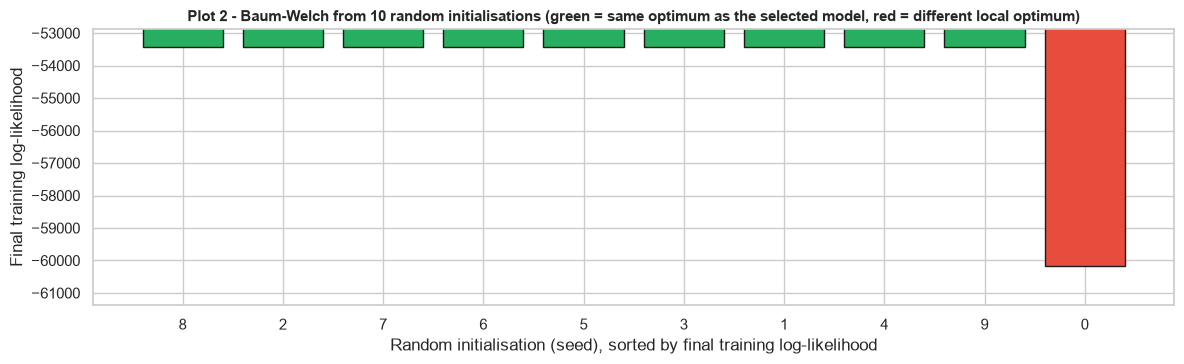

In [5]:
N_INITS = 10
N_STATES = 3


def make_random_hmm(seed, n_states=N_STATES, X=X_train):
    rs = np.random.default_rng(seed)
    model = GaussianHMM(n_components=n_states, covariance_type="full", n_iter=300, tol=1e-3,
                        random_state=seed, init_params="c", params="stmc", implementation="scaling")
    model.startprob_ = rs.dirichlet(np.ones(n_states))
    model.transmat_ = rs.dirichlet(np.ones(n_states), size=n_states)
    model.means_ = X[rs.choice(len(X), n_states, replace=False)]
    return model


def means_original_units(model):
    return scaler.inverse_transform(model.means_)


init_rows, fitted_models = [], {}
for seed in range(N_INITS):
    m = make_random_hmm(seed)
    m.fit(X_train, lengths_train)
    fitted_models[seed] = m
    mob_means = np.sort(means_original_units(m)[:, 0])
    init_rows.append({
        "Seed": seed,
        "Train log-likelihood": m.score(X_train, lengths_train),
        "Stopped by tolerance": m.monitor_.iter < m.n_iter,
        "EM iterations": m.monitor_.iter,
        "Sorted mobility means": np.round(mob_means, 1),
    })

init_df = pd.DataFrame(init_rows).sort_values("Train log-likelihood", ascending=False).reset_index(drop=True)
best_seed = int(init_df.loc[0, "Seed"])
best = fitted_models[best_seed]
best_ll = init_df.loc[0, "Train log-likelihood"]
init_df["Gap to best"] = init_df["Train log-likelihood"] - best_ll
init_df["Same solution as best"] = init_df["Gap to best"].abs() < 1.0

display(init_df)
print(f"Selected model: seed {best_seed} | train log-likelihood = {best_ll:,.2f} "
      f"({best_ll / len(X_train):.4f} per patient-week)")
print(f"{int(init_df['Same solution as best'].sum())}/{N_INITS} initialisations reach the same optimum (|gap| < 1 nat); "
      f"{int(init_df['Stopped by tolerance'].sum())}/{N_INITS} stopped by the tolerance before 300 iterations")

# Plot 2: training log-likelihood reached by each initialisation
fig, ax = plt.subplots(figsize=(12, 3.8))
colors = ["#27AE60" if same else "#E74C3C" for same in init_df["Same solution as best"]]
ax.bar(init_df["Seed"].astype(str), init_df["Train log-likelihood"], color=colors, edgecolor="k")
lo = init_df["Train log-likelihood"].min()
ax.set_ylim(lo - 0.02 * abs(lo), best_ll + 0.01 * abs(best_ll))
ax.set_xlabel("Random initialisation (seed), sorted by final training log-likelihood")
ax.set_ylabel("Final training log-likelihood")
ax.set_title(f"Plot 2 - Baum-Welch from {N_INITS} random initialisations "
             "(green = same optimum as the selected model, red = different local optimum)",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

**Results of the multiple initialisations (Plot 2).** 9 of the 10 random initialisations converge to the **same optimum**: training log-likelihood $-53{,}422.79$, differences below $0.003$ nats, identical sorted mobility means (39.1, 54.1, 70.2), after 47–118 EM iterations. Seed 0 instead stalls at a much worse solution ($-60{,}175$, i.e. $6{,}753$ nats lower) and still had not converged after 300 iterations. In that solution two of the three Gaussians almost coincide (mobility means 43.4 and 45.0), so the model effectively uses only two distinct states. This is the classic local-optimum behaviour of EM and shows why several restarts are needed. We retain the best run (seed 8). Because almost all runs agree, the selected model is not a lucky outlier.

### 2.2 Learned parameters and interpretation of the hidden states

The hidden states returned by `hmmlearn` are arbitrary labels (0, 1, 2). We interpret them **using only the learned emission distributions**: the state whose Gaussian has the lowest mean mobility and functional confidence is interpreted as `Limited`, the intermediate one as `Recovering` and the highest as `Functional`. All parameters below are shown after this relabelling and with emission parameters converted back to the original 0–100 scales.

In [6]:
mu_orig = means_original_units(best)
order = np.argsort(mu_orig[:, 0])                       # ascending mean mobility
emission_map = {int(h): STATE_ORDER[rank] for rank, h in enumerate(order)}
print("Emission-based interpretation of the HMM states:",
      {f"HMM state {h}": lab for h, lab in sorted(emission_map.items())})

D = np.diag(scaler.scale_)
covs_orig = np.array([D @ c @ D for c in best.covars_])

start_df = pd.DataFrame({"Learned pi": best.startprob_[order]}, index=STATE_ORDER).T
trans_df = pd.DataFrame(best.transmat_[np.ix_(order, order)], index=STATE_ORDER, columns=STATE_ORDER)
trans_df.index.name, trans_df.columns.name = "From (week t)", "To (week t+1)"

emis_rows = []
for rank, h in enumerate(order):
    c = covs_orig[h]
    emis_rows.append({
        "Interpreted state": STATE_ORDER[rank],
        "HMM label": int(h),
        "Mean mobility": mu_orig[h, 0],
        "SD mobility": np.sqrt(c[0, 0]),
        "Mean func_conf": mu_orig[h, 1],
        "SD func_conf": np.sqrt(c[1, 1]),
        "Corr(mob, func_conf)": c[0, 1] / np.sqrt(c[0, 0] * c[1, 1]),
    })
emis_df = pd.DataFrame(emis_rows)

print("\nInitial-state probabilities:")
display(start_df)
print("Transition matrix A[i, j] = P(z_{t+1} = j | z_t = i):")
display(trans_df)
print("Emission distributions (bivariate Gaussians, original units):")
display(emis_df)

Emission-based interpretation of the HMM states: {'HMM state 0': 'Limited', 'HMM state 1': 'Functional', 'HMM state 2': 'Recovering'}

Initial-state probabilities:


,Limited,Recovering,Functional
Learned pi,0.6100,0.3537,0.0363


Transition matrix A[i, j] = P(z_{t+1} = j | z_t = i):


To (week t+1),Limited,Recovering,Functional
From (week t),,,
Limited,0.8860,0.1140,0.0000
Recovering,0.0003,0.8617,0.1380
Functional,0.0000,0.0001,0.9999


Emission distributions (bivariate Gaussians, original units):


,Interpreted state,HMM label,Mean mobility,SD mobility,Mean func_conf,SD func_conf,"Corr(mob, func_conf)"
0,Limited,0,39.1265,8.5754,36.6646,9.1837,0.1638
1,Recovering,2,54.1023,7.0670,52.3147,8.1522,-0.1612
2,Functional,1,70.2266,8.8889,69.3636,9.6303,0.1822


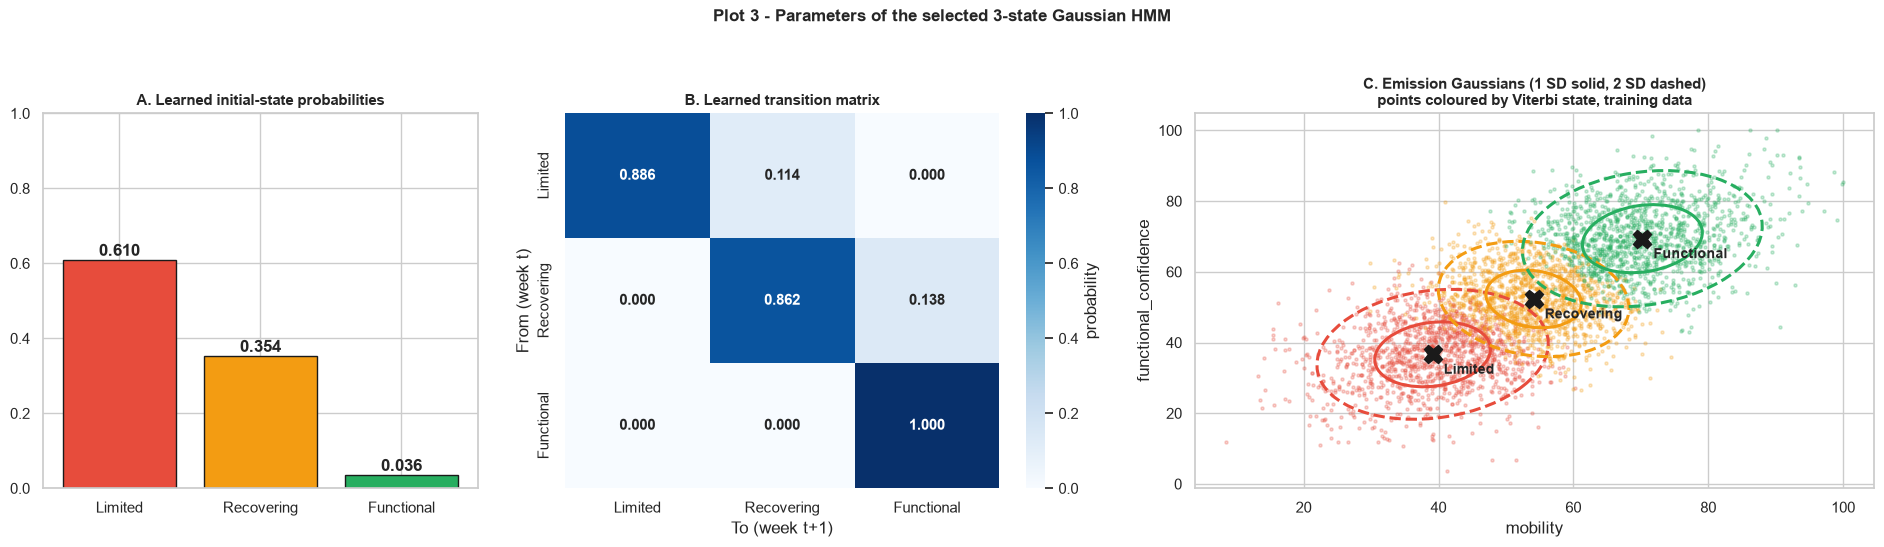

In [7]:
# Plot 3: learned initial distribution, transition matrix and emission Gaussians
_, hidden_train = best.decode(X_train, lengths_train, algorithm="viterbi")
train_decoded = pd.Series(hidden_train).map(emission_map)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.3), gridspec_kw={"width_ratios": [0.8, 1.0, 1.25]})

axes[0].bar(STATE_ORDER, start_df.values.ravel(), color=[STATE_COLORS[s] for s in STATE_ORDER], edgecolor="k")
for i, p in enumerate(start_df.values.ravel()):
    axes[0].text(i, p + 0.01, f"{p:.3f}", ha="center", fontweight="bold")
axes[0].set_ylim(0, 1)
axes[0].set_title("A. Learned initial-state probabilities", fontsize=10.5, fontweight="bold")

sns.heatmap(trans_df, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=axes[1],
            annot_kws={"size": 11, "weight": "bold"}, cbar_kws={"label": "probability"})
axes[1].set_title("B. Learned transition matrix", fontsize=10.5, fontweight="bold")

rs_plot = np.random.default_rng(RANDOM_STATE).choice(len(train_df), 4000, replace=False)
pts = train_df[FEATURES].values[rs_plot]
for s in STATE_ORDER:
    mask = (train_decoded.values[rs_plot] == s)
    axes[2].scatter(pts[mask, 0], pts[mask, 1], s=5, alpha=0.25, color=STATE_COLORS[s])
for rank, h in enumerate(order):
    vals, vecs = np.linalg.eigh(covs_orig[h])
    angle = np.degrees(np.arctan2(vecs[1, -1], vecs[0, -1]))
    for k_sd, ls in [(1, "-"), (2, "--")]:
        axes[2].add_patch(Ellipse(mu_orig[h], 2 * k_sd * np.sqrt(vals[-1]), 2 * k_sd * np.sqrt(vals[0]),
                                  angle=angle, fill=False, lw=2.2, ls=ls, color=STATE_COLORS[STATE_ORDER[rank]]))
    axes[2].plot(*mu_orig[h], "X", ms=13, color="k")
    axes[2].annotate(STATE_ORDER[rank], mu_orig[h], xytext=(8, -14), textcoords="offset points",
                     fontweight="bold", fontsize=10)
axes[2].set_xlabel("mobility")
axes[2].set_ylabel("functional_confidence")
axes[2].set_title("C. Emission Gaussians (1 SD solid, 2 SD dashed)\npoints coloured by Viterbi state, training data",
                  fontsize=10.5, fontweight="bold")
plt.suptitle("Plot 3 - Parameters of the selected 3-state Gaussian HMM", fontsize=12, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### 2.3 Are the learned dynamics plausible?

To judge the learned parameters we compare them with the **empirical** quantities computed from the true `state` labels of the training patients. These labels were *not* used to fit the HMM; they are used here only as a reference for evaluation. We also report the expected time spent in each state before leaving it, $\mathbb{E}[\text{dwell}] = 1/(1 - a_{ii})$ weeks.

,State,Learned pi,Empirical pi (week 0),Learned stay prob.,Empirical stay prob.,Learned E[dwell] (weeks),Empirical E[dwell] (weeks)
0,Limited,0.6100,0.6848,0.8860,0.8536,8.7696,6.8306
1,Recovering,0.3537,0.3143,0.8617,0.8703,7.2310,7.7127
2,Functional,0.0363,0.0010,0.9999,0.9637,7619.8559,27.5721


P(improvement in one week) learned: Limited->Recovering = 0.114, Recovering->Functional = 0.138, Limited->Functional = 0.000
P(setback in one week)    learned: Recovering->Limited = 0.000, Functional->Recovering = 0.000, Functional->Limited = 0.000
P(setback in one week)    empirical: Recovering->Limited = 0.010, Functional->Recovering = 0.036, Functional->Limited = 0.000


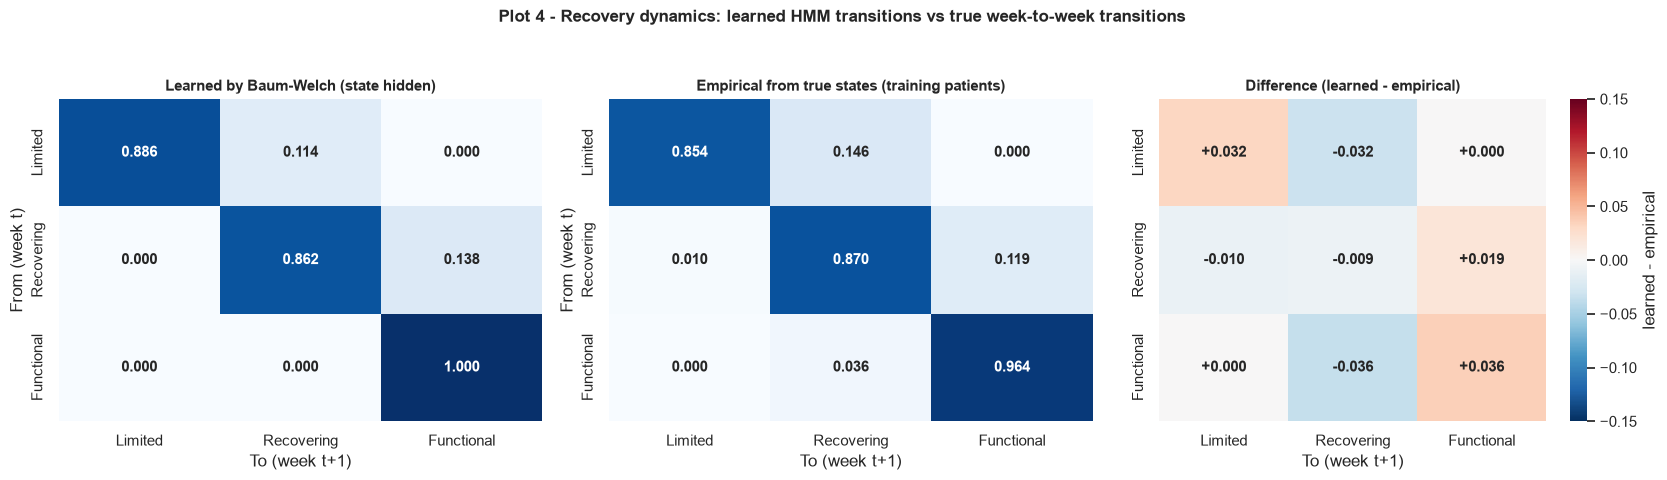

In [8]:
tr = train_df.sort_values(["patient_id", "week"]).copy()
tr["next_state"] = tr.groupby("patient_id")["state"].shift(-1)
emp_trans = (pd.crosstab(tr["state"], tr["next_state"], normalize="index")
             .reindex(index=STATE_ORDER, columns=STATE_ORDER).fillna(0))
emp_start = tr.loc[tr.week == 0, "state"].value_counts(normalize=True).reindex(STATE_ORDER).fillna(0)

cmp_rows = []
for i, s in enumerate(STATE_ORDER):
    cmp_rows.append({
        "State": s,
        "Learned pi": start_df.values.ravel()[i],
        "Empirical pi (week 0)": emp_start[s],
        "Learned stay prob.": trans_df.iloc[i, i],
        "Empirical stay prob.": emp_trans.iloc[i, i],
        "Learned E[dwell] (weeks)": 1 / (1 - trans_df.iloc[i, i]),
        "Empirical E[dwell] (weeks)": 1 / (1 - emp_trans.iloc[i, i]),
    })
display(pd.DataFrame(cmp_rows))

# Improvements (above diagonal) vs setbacks (below diagonal)
A = trans_df.values
E = emp_trans.values
print(f"P(improvement in one week) learned: Limited->Recovering = {A[0,1]:.3f}, Recovering->Functional = {A[1,2]:.3f}, "
      f"Limited->Functional = {A[0,2]:.3f}")
print(f"P(setback in one week)    learned: Recovering->Limited = {A[1,0]:.3f}, Functional->Recovering = {A[2,1]:.3f}, "
      f"Functional->Limited = {A[2,0]:.3f}")
print(f"P(setback in one week)    empirical: Recovering->Limited = {E[1,0]:.3f}, Functional->Recovering = {E[2,1]:.3f}, "
      f"Functional->Limited = {E[2,0]:.3f}")

# Plot 4: learned vs empirical transition matrices
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
sns.heatmap(trans_df, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=axes[0], cbar=False,
            annot_kws={"size": 11, "weight": "bold"})
axes[0].set_title("Learned by Baum-Welch (state hidden)", fontsize=10.5, fontweight="bold")
sns.heatmap(emp_trans, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=axes[1], cbar=False,
            annot_kws={"size": 11, "weight": "bold"})
axes[1].set_title("Empirical from true states (training patients)", fontsize=10.5, fontweight="bold")
axes[1].set_xlabel("To (week t+1)")
axes[1].set_ylabel("From (week t)")
diff = trans_df - emp_trans
sns.heatmap(diff, annot=True, fmt="+.3f", cmap="RdBu_r", center=0, vmin=-0.15, vmax=0.15, ax=axes[2],
            annot_kws={"size": 11, "weight": "bold"}, cbar_kws={"label": "learned - empirical"})
axes[2].set_title("Difference (learned - empirical)", fontsize=10.5, fontweight="bold")
axes[2].set_xlabel("To (week t+1)")
axes[2].set_ylabel("")
plt.suptitle("Plot 4 - Recovery dynamics: learned HMM transitions vs true week-to-week transitions",
             fontsize=12, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

**Interpretation of the hidden states.** Ordering the learned Gaussians by their means gives a clear correspondence: **Limited** (mobility 39.1, functional confidence 36.7), **Recovering** (54.1, 52.3) and **Functional** (70.2, 69.4). These means are very close to the true-state means of Section 1.1 (40.5/37.7, 56.1/54.5, 71.5/71.0), even though the labels were never used. The ellipses in Plot 3C are ordered along the diagonal with the same ordering on both variables, so the emissions are fully consistent with this interpretation. The learned emission SDs (7.1–9.6) are somewhat smaller than the true within-state SDs (≈ 9.6–10.1), and the within-state correlations are weaker (−0.16 to 0.18 vs 0.26–0.32). The HMM assigns ambiguous points to whichever state fits them best, which makes each fitted Gaussian slightly "tighter" than the true class distributions.

**Initial distribution.** 61.0% of patients start in Limited, 35.4% in Recovering and 3.6% in Functional, compared with the empirical 68.5% / 31.4% / 0.1%. The HMM classifies some week-0 patients with relatively good scores as Recovering or Functional.

**Transition matrix (Plots 3B and 4).**
* *Persistence:* the diagonal dominates (0.886, 0.862 and ≈1.000), so from one week to the next patients most likely remain in the same state. This is plausible for weekly rehabilitation, since recovery is gradual. The expected stays in Limited (8.8 weeks) and Recovering (7.2 weeks) are close to the empirical values (6.8 and 7.7).
* *Improvements:* recovery is represented as a **left-to-right progression**: Limited → Recovering (0.114, empirical 0.146) and Recovering → Functional (0.138, empirical 0.120). There is no direct jump Limited → Functional (0.000, empirically also 0). This ordered structure emerged from the data without being imposed.
* *Setbacks:* setbacks are **essentially not represented**. Recovering → Limited is 0.0003 (empirical 0.010) and Functional → Recovering is 0.0001 (empirical 0.036), so `Functional` has become an (almost) **absorbing state**: its expected stay is about 7,600 weeks vs 27.6 empirically. Setbacks are rare and usually last a single week. With overlapping emission distributions, a one-week dip in the measurements is explained more cheaply as emission noise than by two low-probability transitions (down and back up). The likelihood therefore drives these probabilities towards zero.

The training contingency table in Section 3.1 points to a related effect: the HMM's `Functional` state also absorbs 3,228 training weeks that are truly `Recovering` (late-recovery weeks with good scores). The learned dynamics therefore describe a plausible monotone recovery, but a smoother and more optimistic one than the true process.

### 2.4 Why selecting a model only by its training likelihood can be problematic

Choosing among the 10 runs by training log-likelihood is reasonable here, because all candidates share the **same** architecture (3 states, full covariances) and we only want to escape poor local optima of EM. It becomes problematic when the training likelihood is used to compare models of **different complexity** or as a measure of quality:

* the training likelihood always increases (or stays equal) when parameters are added, e.g. more hidden states or richer covariances, so it systematically favours over-complex models (over-fitting);
* it is evaluated on the same patients used for fitting, so it is an optimistic estimate of how well the model describes *new* patients;
* a higher likelihood does not guarantee states that are clinically meaningful or that match the true recovery states.

Alternatives are (i) information criteria that penalise complexity (**BIC**/AIC), (ii) the log-likelihood on **held-out validation patients**, ideally in a patient-grouped cross-validation, and (iii) domain-based checks of the learned parameters. The experiment below illustrates this: we split the **training patients** further into 80% fitting / 20% validation patients (the test set is not touched) and fit HMMs with 2–5 states.

,Hidden states K,Free parameters,Train LL / obs,Validation LL / obs,BIC (fit set)
0,2,13,-2.0527,-2.0368,96691.6624
1,3,23,-1.8222,-1.7984,85949.9383
2,4,35,-1.6725,-1.6441,79028.2522
3,5,49,-1.5686,-1.5330,74279.1709


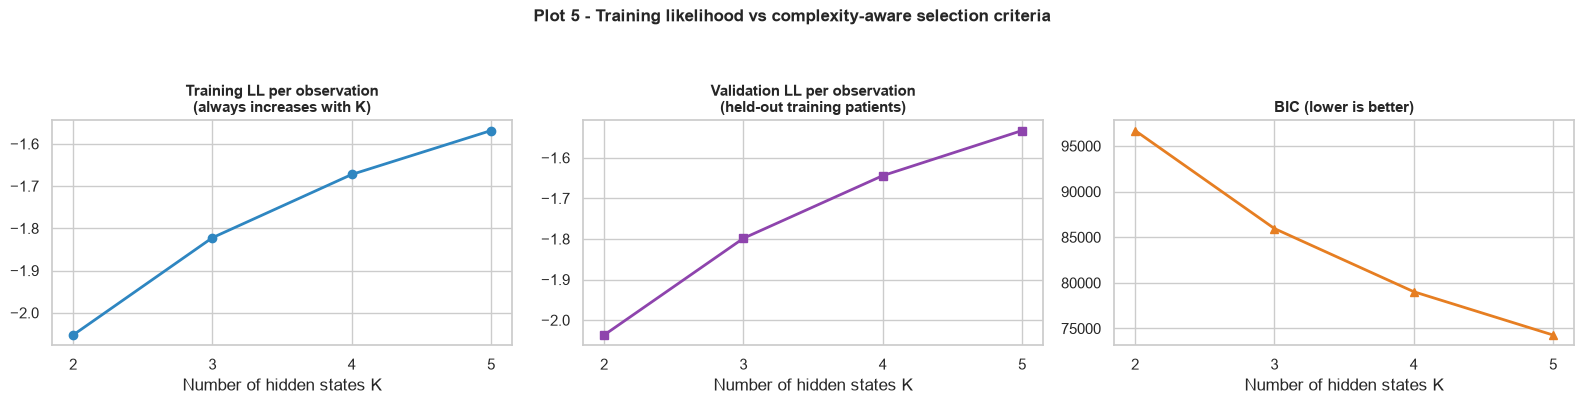

In [9]:
rs_val = np.random.default_rng(RANDOM_STATE + 1)
val_pids = set(rs_val.choice(train_pids, size=int(round(0.2 * len(train_pids))), replace=False))
fit_mask = ~train_df["patient_id"].isin(val_pids)
X_fit, len_fit = to_sequences(train_df[fit_mask])
X_val, len_val = to_sequences(train_df[~fit_mask])


def n_free_params(k, d=len(FEATURES)):
    return (k - 1) + k * (k - 1) + k * d + k * d * (d + 1) // 2


sel_rows = []
for k in [2, 3, 4, 5]:
    runs = []
    for seed in range(2):
        # k-means initialisation of the means (hmmlearn default) for a fast, stable comparison across K
        m = GaussianHMM(n_components=k, covariance_type="full", n_iter=300, tol=1e-3,
                        random_state=seed, implementation="scaling")
        m.fit(X_fit, len_fit)
        runs.append((m.score(X_fit, len_fit), m))
    ll_fit, m_k = max(runs, key=lambda r: r[0])
    p = n_free_params(k)
    sel_rows.append({
        "Hidden states K": k,
        "Free parameters": p,
        "Train LL / obs": ll_fit / len(X_fit),
        "Validation LL / obs": m_k.score(X_val, len_val) / len(X_val),
        "BIC (fit set)": -2 * ll_fit + p * np.log(len(X_fit)),
    })
sel_df = pd.DataFrame(sel_rows)
display(sel_df)

# Plot 5
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].plot(sel_df["Hidden states K"], sel_df["Train LL / obs"], "-o", color="#2E86C1", lw=2)
axes[0].set_title("Training LL per observation\n(always increases with K)", fontsize=10.5, fontweight="bold")
axes[1].plot(sel_df["Hidden states K"], sel_df["Validation LL / obs"], "-s", color="#8E44AD", lw=2)
axes[1].set_title("Validation LL per observation\n(held-out training patients)", fontsize=10.5, fontweight="bold")
axes[2].plot(sel_df["Hidden states K"], sel_df["BIC (fit set)"], "-^", color="#E67E22", lw=2)
axes[2].set_title("BIC (lower is better)", fontsize=10.5, fontweight="bold")
for ax in axes:
    ax.set_xticks(sel_df["Hidden states K"])
    ax.set_xlabel("Number of hidden states K")
plt.suptitle("Plot 5 - Training likelihood vs complexity-aware selection criteria", fontsize=12, fontweight="bold", y=1.06)
plt.tight_layout()
plt.show()

**Results (Plot 5).** As expected, the training log-likelihood per observation increases monotonically with the number of states (−2.053 → −1.822 → −1.673 → −1.569 for K = 2…5). Interestingly, in this dataset the complexity-aware criteria also keep improving: BIC decreases (96,692 → 85,950 → 79,028 → 74,279) and the validation log-likelihood increases (−2.037 → −1.533). Validation values are slightly higher than training values only because the validation patients happen to be somewhat easier to fit; what matters is the trend across K.

This shows the main problem with purely likelihood-based selection. The criteria measure how well the model describes the **density** of the measurements, not whether its states correspond to the three clinical recovery states. Patients differ systematically in their measurement levels (for example patient 1316 in Plot 8), and extra hidden states can capture such sub-groups and intermediate stages. This improves the fit while making the states harder to interpret clinically. We keep **K = 3**, as required by the milestone and because it matches the three recovery states. Selecting a model is therefore a trade-off between statistical criteria and clinical interpretability. Validation on held-out patients and BIC are better guides than the training likelihood, but domain knowledge should also be taken into account.

---
## Task 3: Inference and Evaluation on the Test Patients

### 3.1 Viterbi decoding and state mapping

For each of the 900 test patients we run the **Viterbi algorithm**, which returns the single most likely sequence of hidden states $\hat z_{0:13} = \arg\max_{z_{0:13}} P(z_{0:13} \mid x_{0:13})$ under the learned model (passing `lengths` makes `hmmlearn` decode every patient as a separate sequence).

**Mapping.** The HMM labels are mapped to recovery states with the **emission-based rule** defined in Section 2.2 (ordering the learned Gaussians by mean mobility/functional confidence). This mapping uses only the learned parameters, never the true labels. As a cross-check we also compute the mapping that maximises agreement with the true states **on the training patients** (Hungarian algorithm on the train confusion table); both should coincide.

In [10]:
_, hidden_test = best.decode(X_test, lengths_test, algorithm="viterbi")

test_out = test_df[["patient_id", "week", "state"] + FEATURES].copy()
test_out["hmm_state"] = hidden_test
test_out["decoded"] = test_out["hmm_state"].map(emission_map)

# Cross-check: Hungarian mapping estimated on TRAINING patients
ct_train = pd.crosstab(pd.Series(hidden_train, name="HMM state"), train_df["state"].rename("True state"))
r_idx, c_idx = linear_sum_assignment(-ct_train.values)
hungarian_map = {int(ct_train.index[r]): ct_train.columns[c] for r, c in zip(r_idx, c_idx)}
print("Training-set contingency table (HMM state x true state):")
display(ct_train)
print(f"Emission-based mapping : {dict(sorted(emission_map.items()))}")
print(f"Hungarian (train) map  : {dict(sorted(hungarian_map.items()))}")
print(f"Mappings agree: {emission_map == hungarian_map}")

Training-set contingency table (HMM state x true state):


True state,Functional,Limited,Recovering
HMM state,,,
0,0,7788,1526
1,6697,4,3228
2,455,1725,7977


Emission-based mapping : {0: 'Limited', 1: 'Functional', 2: 'Recovering'}
Hungarian (train) map  : {0: 'Limited', 1: 'Functional', 2: 'Recovering'}
Mappings agree: True


### 3.2 Confusion matrix and accuracy

Besides the Viterbi accuracy we report three reference points that help to interpret it:
* **Majority class:** always predicting the most frequent state in the training data.
* **Emission only (no temporal model):** each week is classified independently by the learned Gaussian with the highest density, i.e. the same emissions but *without* the Markov chain (comparable to the GMM view of M1).
* **Posterior decoding:** the forward–backward algorithm gives $P(z_t \mid x_{0:13})$ for every week; we take the most probable state per week.

,Method,Uses time?,Test accuracy
0,Majority class (always 'Recovering'),no,0.4252
1,Emission only (per-week Gaussian argmax),no,0.7500
2,HMM posterior decoding (forward-backward),yes,0.7625
3,HMM Viterbi decoding (main result),yes,0.7617


Viterbi decoding - per-state metrics on the 12,600 test patient-weeks:
              precision    recall  f1-score   support

     Limited     0.8536    0.8249    0.8390      4312
  Recovering     0.7797    0.6130    0.6864      5357
  Functional     0.6532    0.9406    0.7710      2931

    accuracy                         0.7617     12600
   macro avg     0.7622    0.7929    0.7655     12600
weighted avg     0.7755    0.7617    0.7583     12600



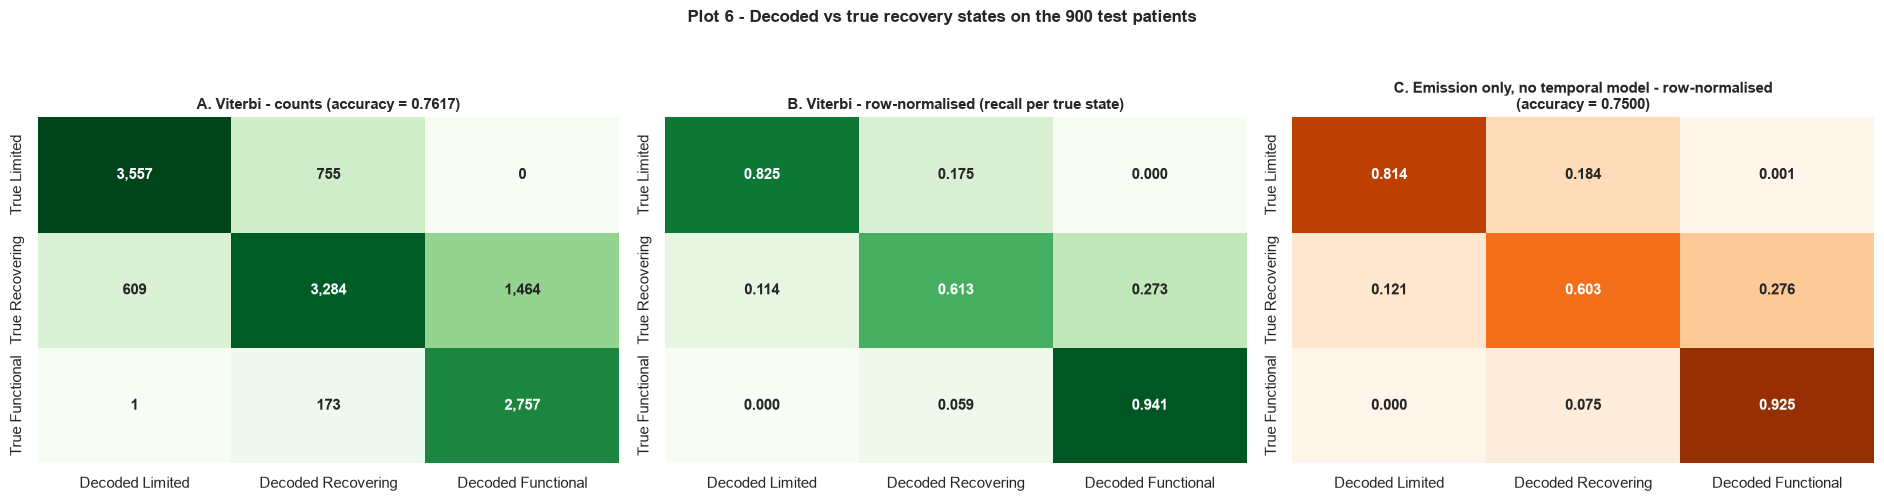

In [11]:
y_true = test_out["state"].values
y_vit = test_out["decoded"].values

# Emission-only classification (no transitions)
log_dens = np.column_stack([multivariate_normal(best.means_[h], best.covars_[h]).logpdf(X_test)
                            for h in range(N_STATES)])
y_emis = pd.Series(log_dens.argmax(axis=1)).map(emission_map).values

# Posterior (forward-backward) decoding
post = best.predict_proba(X_test, lengths_test)
y_post = pd.Series(post.argmax(axis=1)).map(emission_map).values
test_out["decoded_emission_only"] = y_emis
test_out["max_posterior"] = post.max(axis=1)

majority = train_df["state"].mode()[0]
acc_df = pd.DataFrame([
    {"Method": f"Majority class (always '{majority}')", "Uses time?": "no", "Test accuracy": (y_true == majority).mean()},
    {"Method": "Emission only (per-week Gaussian argmax)", "Uses time?": "no", "Test accuracy": accuracy_score(y_true, y_emis)},
    {"Method": "HMM posterior decoding (forward-backward)", "Uses time?": "yes", "Test accuracy": accuracy_score(y_true, y_post)},
    {"Method": "HMM Viterbi decoding (main result)", "Uses time?": "yes", "Test accuracy": accuracy_score(y_true, y_vit)},
])
display(acc_df)

print("Viterbi decoding - per-state metrics on the 12,600 test patient-weeks:")
print(classification_report(y_true, y_vit, labels=STATE_ORDER, digits=4))

cm = confusion_matrix(y_true, y_vit, labels=STATE_ORDER)
cm_df = pd.DataFrame(cm, index=[f"True {s}" for s in STATE_ORDER], columns=[f"Decoded {s}" for s in STATE_ORDER])
cm_emis = confusion_matrix(y_true, y_emis, labels=STATE_ORDER)

# Plot 6: confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
sns.heatmap(cm_df, annot=True, fmt=",d", cmap="Greens", ax=axes[0], cbar=False, annot_kws={"size": 11, "weight": "bold"})
axes[0].set_title(f"A. Viterbi - counts (accuracy = {accuracy_score(y_true, y_vit):.4f})", fontsize=10.5, fontweight="bold")
sns.heatmap(cm_df.div(cm_df.sum(axis=1), axis=0), annot=True, fmt=".3f", cmap="Greens", vmin=0, vmax=1, ax=axes[1],
            cbar=False, annot_kws={"size": 11, "weight": "bold"})
axes[1].set_title("B. Viterbi - row-normalised (recall per true state)", fontsize=10.5, fontweight="bold")
sns.heatmap(pd.DataFrame(cm_emis / cm_emis.sum(axis=1, keepdims=True), index=cm_df.index, columns=cm_df.columns),
            annot=True, fmt=".3f", cmap="Oranges", vmin=0, vmax=1, ax=axes[2], cbar=False,
            annot_kws={"size": 11, "weight": "bold"})
axes[2].set_title(f"C. Emission only, no temporal model - row-normalised\n(accuracy = {accuracy_score(y_true, y_emis):.4f})",
                  fontsize=10.5, fontweight="bold")
for ax in axes:
    ax.set_ylabel("")
plt.suptitle("Plot 6 - Decoded vs true recovery states on the 900 test patients", fontsize=12, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

### 3.3 Where in the trajectories do the errors occur?

We locate the errors along the trajectories in three ways: (i) accuracy per rehabilitation week, (ii) accuracy as a function of the distance (in weeks) to the nearest **true** state change of that patient, and (iii) how well the decoded sequences reproduce the timing of recovery and the true **setbacks** (a week in which the true state moves to a worse state).

Accuracy by distance to the nearest true state change:


,n,Viterbi_acc,EmissionOnly_acc
dist_bin,,,
0 (adjacent to change),2531,0.5642,0.5697
1 week away,2053,0.6965,0.7019
2 weeks away,1776,0.7686,0.7556
>= 3 weeks away,4980,0.8474,0.8211
no change in trajectory,1260,0.9167,0.9016


Patients reaching Functional (true): 537 / 900 | (decoded): 569 / 900
Decoded minus true first Functional week: mean = -1.923, |lag| = 0 for 15.8%, |lag| <= 1 for 40.7%
Average number of state changes per patient: true = 1.501, decoded = 1.039
Patients with >= 1 true setback: 139 (152 setbacks) | decoded setbacks in total: 0 | true setbacks recovered by Viterbi (within +/-1 week): 0 / 139 patients
Patients decoded perfectly (0 errors in 14 weeks): 14.1%
Accuracy per rehabilitation week:


week,0,1,2,3,4,5,6,7,8,9,10,11,12,13
Viterbi,0.7811,0.7744,0.7556,0.7422,0.7622,0.7400,0.7600,0.7544,0.7544,0.7600,0.7356,0.7533,0.7900,0.8011
Emission_only,0.7767,0.7556,0.7489,0.7267,0.7456,0.7300,0.7367,0.7244,0.7433,0.7533,0.7389,0.7367,0.7811,0.8022


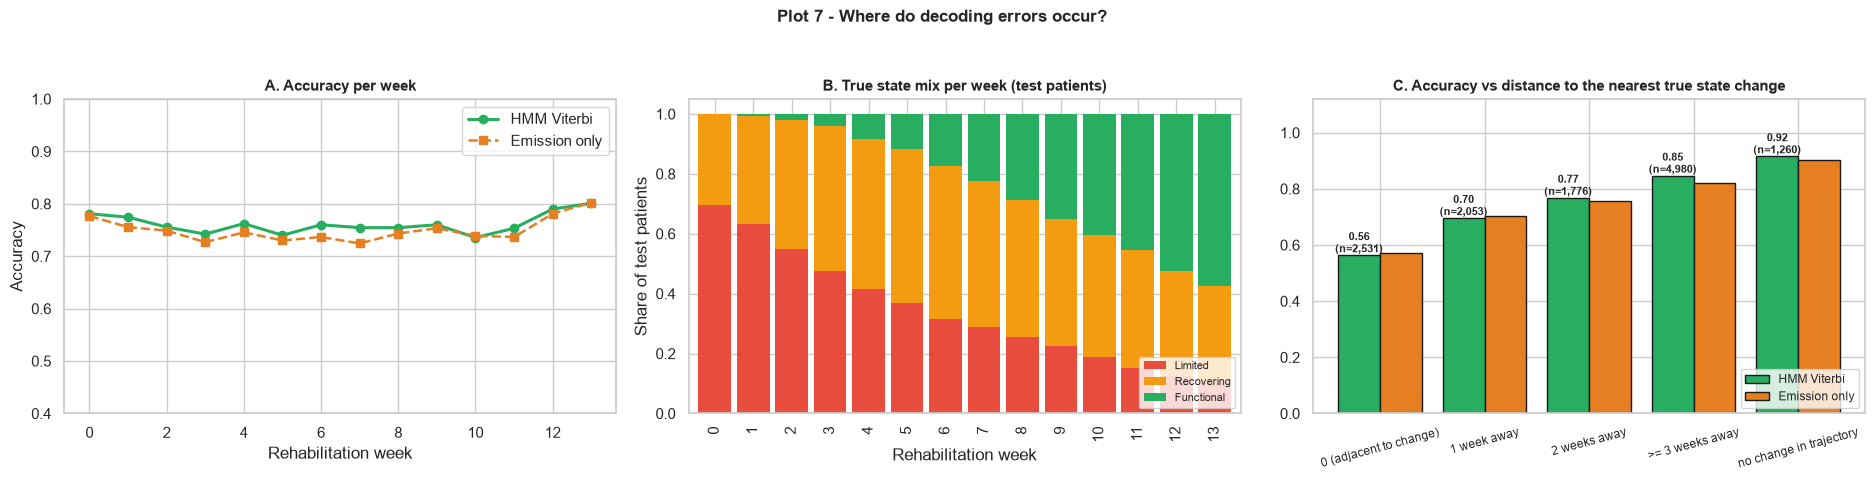

In [12]:
test_out = test_out.sort_values(["patient_id", "week"]).reset_index(drop=True)
test_out["correct"] = test_out["state"] == test_out["decoded"]
test_out["correct_emis"] = test_out["state"] == test_out["decoded_emission_only"]
test_out["rank_true"] = test_out["state"].map(STATE_RANK)
test_out["rank_dec"] = test_out["decoded"].map(STATE_RANK)


def dist_to_change(g):
    ranks = g["rank_true"].values
    change_weeks = np.where(np.diff(ranks) != 0)[0] + 1      # first week in the new state
    if len(change_weeks) == 0:
        return pd.Series(np.full(len(g), np.inf), index=g.index)
    w = g["week"].values
    # distance to the boundary between week c-1 and week c: weeks c-1 and c both have distance 0
    d = np.min(np.abs(w[:, None] - (change_weeks[None, :] - 0.5)), axis=1) - 0.5
    return pd.Series(d, index=g.index)


test_out["dist_change"] = test_out.groupby("patient_id", group_keys=False).apply(dist_to_change)
bins = [-0.1, 0.1, 1.1, 2.1, np.inf]
labels = ["0 (adjacent to change)", "1 week away", "2 weeks away", ">= 3 weeks away"]
test_out["dist_bin"] = pd.cut(test_out["dist_change"], bins=bins, labels=labels).astype(str)
test_out.loc[np.isinf(test_out["dist_change"]), "dist_bin"] = "no change in trajectory"

dist_df = (test_out.groupby("dist_bin")
           .agg(n=("correct", "size"), Viterbi_acc=("correct", "mean"), EmissionOnly_acc=("correct_emis", "mean"))
           .reindex(labels + ["no change in trajectory"]))
print("Accuracy by distance to the nearest true state change:")
display(dist_df)

# Timing of recovery and setbacks
per_pat = []
for pid, g in test_out.groupby("patient_id"):
    rt, rd = g["rank_true"].values, g["rank_dec"].values
    first_true = g["week"].values[rt == 2].min() if (rt == 2).any() else np.nan
    first_dec = g["week"].values[rd == 2].min() if (rd == 2).any() else np.nan
    true_sb = np.where(np.diff(rt) < 0)[0] + 1
    dec_sb = np.where(np.diff(rd) < 0)[0] + 1
    per_pat.append({
        "patient_id": pid,
        "first_functional_true": first_true,
        "first_functional_dec": first_dec,
        "n_true_setbacks": len(true_sb),
        "n_dec_setbacks": len(dec_sb),
        "setback_detected_pm1": any(np.abs(dec_sb[:, None] - true_sb[None, :]).min(axis=0) <= 1) if len(true_sb) and len(dec_sb) else False,
        "n_true_changes": int((np.diff(rt) != 0).sum()),
        "n_dec_changes": int((np.diff(rd) != 0).sum()),
        "errors": int((rt != rd).sum()),
    })
per_pat = pd.DataFrame(per_pat)

both = per_pat.dropna(subset=["first_functional_true", "first_functional_dec"])
lag = both["first_functional_dec"] - both["first_functional_true"]
print(f"Patients reaching Functional (true): {per_pat['first_functional_true'].notna().sum()} / {len(per_pat)} | "
      f"(decoded): {per_pat['first_functional_dec'].notna().sum()} / {len(per_pat)}")
print(f"Decoded minus true first Functional week: mean = {lag.mean():+.3f}, |lag| = 0 for {(lag == 0).mean():.1%}, "
      f"|lag| <= 1 for {(lag.abs() <= 1).mean():.1%}")
print(f"Average number of state changes per patient: true = {per_pat['n_true_changes'].mean():.3f}, "
      f"decoded = {per_pat['n_dec_changes'].mean():.3f}")
sb = per_pat[per_pat["n_true_setbacks"] > 0]
print(f"Patients with >= 1 true setback: {len(sb)} ({per_pat['n_true_setbacks'].sum()} setbacks) | "
      f"decoded setbacks in total: {per_pat['n_dec_setbacks'].sum()} | "
      f"true setbacks recovered by Viterbi (within +/-1 week): {sb['setback_detected_pm1'].sum()} / {len(sb)} patients")
print(f"Patients decoded perfectly (0 errors in 14 weeks): {(per_pat['errors'] == 0).mean():.1%}")

# Plot 7: accuracy by week and by distance to change
week_acc = test_out.groupby("week").agg(Viterbi=("correct", "mean"), Emission_only=("correct_emis", "mean"))
state_mix = pd.crosstab(test_out["week"], test_out["state"], normalize="index").reindex(columns=STATE_ORDER)
print("Accuracy per rehabilitation week:")
display(week_acc.T)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
axes[0].plot(week_acc.index, week_acc["Viterbi"], "-o", lw=2.2, color="#27AE60", label="HMM Viterbi")
axes[0].plot(week_acc.index, week_acc["Emission_only"], "--s", lw=1.8, color="#E67E22", label="Emission only")
axes[0].set_ylim(0.4, 1.0)
axes[0].set_xlabel("Rehabilitation week")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("A. Accuracy per week", fontsize=10.5, fontweight="bold")
axes[0].legend()

state_mix.plot(kind="bar", stacked=True, ax=axes[1], color=[STATE_COLORS[s] for s in STATE_ORDER], width=0.85, edgecolor="none")
axes[1].set_xlabel("Rehabilitation week")
axes[1].set_ylabel("Share of test patients")
axes[1].set_title("B. True state mix per week (test patients)", fontsize=10.5, fontweight="bold")
axes[1].legend(fontsize=8, loc="lower right")

x = np.arange(len(dist_df))
axes[2].bar(x - 0.2, dist_df["Viterbi_acc"], 0.4, color="#27AE60", edgecolor="k", label="HMM Viterbi")
axes[2].bar(x + 0.2, dist_df["EmissionOnly_acc"], 0.4, color="#E67E22", edgecolor="k", label="Emission only")
for i, (a, n) in enumerate(zip(dist_df["Viterbi_acc"], dist_df["n"])):
    axes[2].text(i - 0.2, a + 0.01, f"{a:.2f}\n(n={n:,})", ha="center", fontsize=8, fontweight="bold")
axes[2].set_xticks(x)
axes[2].set_xticklabels(dist_df.index, rotation=15, fontsize=8.5)
axes[2].set_ylim(0, 1.12)
axes[2].set_title("C. Accuracy vs distance to the nearest true state change", fontsize=10.5, fontweight="bold")
axes[2].legend(fontsize=8.5, loc="lower right")
plt.suptitle("Plot 7 - Where do decoding errors occur?", fontsize=12, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

### 3.4 Decoded vs true trajectories for three test patients

We show three representative test patients: one with a **true setback**, one with a typical **steady recovery**, and the patient with the **largest number of decoding errors**. The top row shows the two observed measurements; the bottom row compares the true and the Viterbi-decoded state sequences.

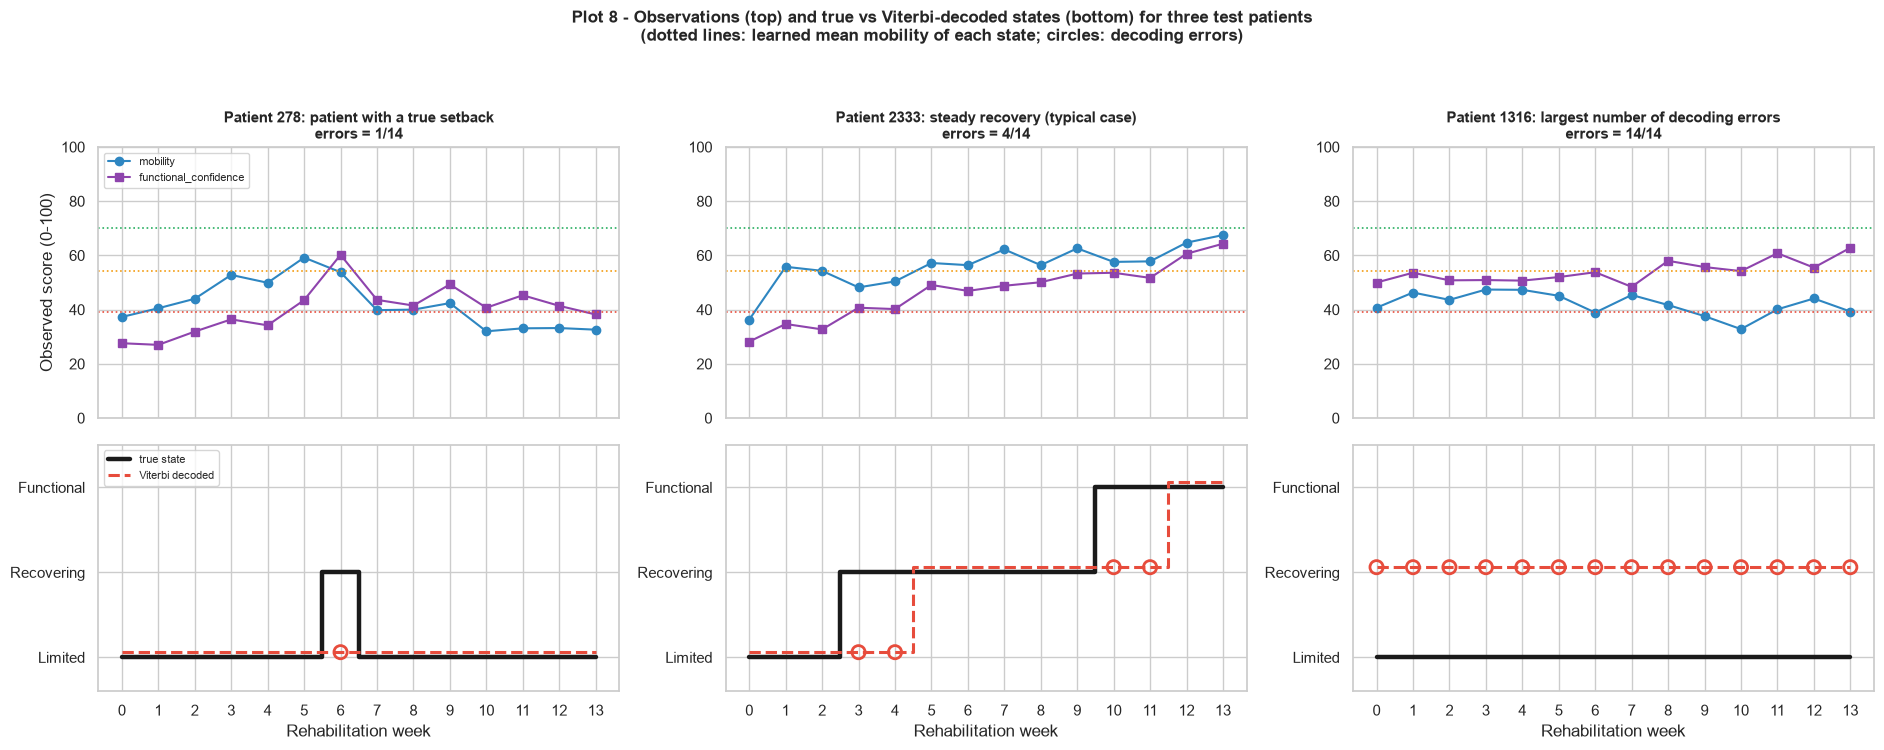

Patient 278 (patient with a true setback) - mean mobility = 42.2, mean functional_confidence = 40.1
  true   : Lim Lim Lim Lim Lim Lim Rec Lim Lim Lim Lim Lim Lim Lim
  decoded: Lim Lim Lim Lim Lim Lim Lim Lim Lim Lim Lim Lim Lim Lim
Patient 2333 (steady recovery (typical case)) - mean mobility = 56.2, mean functional_confidence = 46.8
  true   : Lim Lim Lim Rec Rec Rec Rec Rec Rec Rec Fun Fun Fun Fun
  decoded: Lim Lim Lim Lim Lim Rec Rec Rec Rec Rec Rec Rec Fun Fun
Patient 1316 (largest number of decoding errors) - mean mobility = 42.2, mean functional_confidence = 54.1
  true   : Lim Lim Lim Lim Lim Lim Lim Lim Lim Lim Lim Lim Lim Lim
  decoded: Rec Rec Rec Rec Rec Rec Rec Rec Rec Rec Rec Rec Rec Rec


In [13]:
setback_pats = per_pat[(per_pat["n_true_setbacks"] > 0)].sort_values(["setback_detected_pm1", "errors"], ascending=[False, True])
steady_pats = per_pat[(per_pat["n_true_setbacks"] == 0) & (per_pat["n_true_changes"] == 2)].sort_values("errors")
pid_setback = int(setback_pats.iloc[0]["patient_id"])
pid_steady = int(steady_pats.iloc[len(steady_pats) // 2]["patient_id"])
pid_worst = int(per_pat.sort_values(["errors", "patient_id"], ascending=[False, True]).iloc[0]["patient_id"])
examples = [(pid_setback, "patient with a true setback"),
            (pid_steady, "steady recovery (typical case)"),
            (pid_worst, "largest number of decoding errors")]

fig, axes = plt.subplots(2, 3, figsize=(19, 7.2), sharex=True, gridspec_kw={"height_ratios": [1.1, 1.0]})
for j, (pid, desc) in enumerate(examples):
    g = test_out[test_out.patient_id == pid]
    ax = axes[0, j]
    ax.plot(g["week"], g["mobility"], "-o", color="#2E86C1", label="mobility")
    ax.plot(g["week"], g["functional_confidence"], "-s", color="#8E44AD", label="functional_confidence")
    for rank, h in enumerate(order):
        ax.axhline(mu_orig[h, 0], color=STATE_COLORS[STATE_ORDER[rank]], ls=":", lw=1.2)
    ax.set_ylim(0, 100)
    ax.set_title(f"Patient {pid}: {desc}\nerrors = {int((~g['correct']).sum())}/14", fontsize=10.5, fontweight="bold")
    if j == 0:
        ax.set_ylabel("Observed score (0-100)")
        ax.legend(fontsize=8, loc="upper left")

    ax = axes[1, j]
    ax.step(g["week"], g["rank_true"], where="mid", lw=3.2, color="k", label="true state")
    ax.step(g["week"], g["rank_dec"] + 0.06, where="mid", lw=2.2, ls="--", color="#E74C3C", label="Viterbi decoded")
    wrong = g[~g["correct"]]
    ax.scatter(wrong["week"], wrong["rank_dec"] + 0.06, s=90, facecolors="none", edgecolors="#E74C3C", lw=2, zorder=5)
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(STATE_ORDER)
    ax.set_ylim(-0.4, 2.5)
    ax.set_xlabel("Rehabilitation week")
    ax.set_xticks(range(14))
    if j == 0:
        ax.legend(fontsize=8, loc="upper left")
plt.suptitle("Plot 8 - Observations (top) and true vs Viterbi-decoded states (bottom) for three test patients\n"
             "(dotted lines: learned mean mobility of each state; circles: decoding errors)",
             fontsize=12, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

for pid, desc in examples:
    g = test_out[test_out.patient_id == pid]
    print(f"Patient {pid} ({desc}) - mean mobility = {g['mobility'].mean():.1f}, "
          f"mean functional_confidence = {g['functional_confidence'].mean():.1f}")
    print("  true   :", " ".join(s[:3] for s in g["state"]))
    print("  decoded:", " ".join(s[:3] for s in g["decoded"]))

**Overall performance.** Viterbi decoding reaches an accuracy of **0.762** on the 12,600 test patient-weeks, far above the majority-class baseline (0.425). Posterior decoding gives practically the same result (0.763). Classifying each week independently with the same Gaussians already reaches 0.750, so the temporal model adds only **about 1.2 percentage points** here. Most of the information comes from the emissions, and the Markov chain mainly smooths isolated noisy weeks.

**Which states are confused (Plot 6)?**
* The weakest state is **Recovering** (recall 0.613). Of its 5,357 test weeks, 1,464 are decoded as Functional and 609 as Limited. Recovering is the intermediate state, so its emission distribution overlaps with both neighbours.
* **Functional** has a high recall (0.941) but a low precision (0.653). Most decoded-Functional errors are true Recovering weeks. This mirrors the absorbing Functional state learned in Task 2: the model reaches Functional too readily and then never leaves.
* Limited ↔ Recovering errors also occur (755 + 609 weeks). Limited is never confused with Functional (only 1 week), which confirms the ordered structure of the states.

**Where do errors occur (Plot 7)?**
* Errors concentrate **around state changes**. Accuracy is only 0.564 for weeks adjacent to a true change, rising to 0.697 (1 week away), 0.769 (2 weeks) and 0.847 (≥ 3 weeks away). It reaches 0.917 for patients whose state never changes. Around a change the measurements are naturally intermediate, and the exact timing of the switch is hard to pinpoint.
* Per week, accuracy is lowest in the middle of rehabilitation (about 0.74–0.76 in weeks 3–11, when all three states coexist) and highest at the start (0.78) and at the end (0.79–0.80 in weeks 12–13), when one state dominates. The Viterbi curve lies on or above the emission-only curve in almost every week.

**Does the HMM capture gradual recovery and setbacks?**
* *Gradual recovery: partially.* Decoded trajectories follow the correct monotone order (Limited → Recovering → Functional), as patient 2333 shows. However, they change state less often than the truth (1.04 vs 1.50 changes per patient), and the timing is imprecise. Among patients who reach Functional in both sequences, the decoded first Functional week is on average 1.9 weeks **too early**, and it is correct within ±1 week for only 40.7% of them. For patient 2333 the decoded changes instead lag the true ones by two weeks, because evidence has to accumulate before Viterbi switches state.
* *Setbacks: no.* The 900 test patients contain 152 true setbacks (in 139 patients), but Viterbi decodes **none**. This follows directly from the near-zero backward transition probabilities: for patient 278, the one-week return to Recovering in week 6 is decoded as Limited.
* Temporal smoothing can also **amplify a systematic error**. Patient 1316 is truly Limited for all 14 weeks and has Limited-like mobility (≈ 42), but a functional confidence around 54, typical of Recovering. Because the HMM uses the same emission parameters for every patient and favours staying in the same state, the whole sequence is decoded as Recovering (14/14 errors). Only 14.1% of the test patients are decoded without any error.

### 3.5 Limitations of the HMM assumptions

The observed errors can be traced back to the assumptions of the model:

* **First-order, time-homogeneous Markov chain.** The same transition matrix is used for every patient and every week. In reality the probability of improving depends on baseline factors (`risk_score`, injury severity, comorbidities), on the time since the start of rehabilitation (Plot 7B shows that transitions to Functional become far more frequent later on) and on the **intervention** applied each week. None of this enters the model. The Markov assumption also ignores how long the patient has already been in a state.
* **Rare events are under-estimated by maximum likelihood.** With few, short setbacks the estimated backward transitions collapse to ≈ 0, and Functional becomes absorbing. Priors on the transition matrix (`transmat_prior`) or structural constraints could keep small but non-zero setback probabilities.
* **Emissions depend only on the current state and are shared by all patients.** The model assumes that, given the state, the weekly measurements are independent over time and identically distributed across patients. Patient-specific baselines (patient 1316) violate this. They create correlation between the weeks of the same patient that the HMM can only explain by switching states. Hierarchical/mixed-effects HMMs or patient-level covariates could address this.
* **Overlapping Gaussian emissions and only two measurements.** Adjacent states differ by only about 1.5–1.7 within-state SDs in each variable, so weeks near the boundaries are intrinsically ambiguous. This explains the low accuracy around state changes. Adding further informative measurements (e.g. `activity`, `pain`) could reduce the overlap.
* **Discrete states for a continuous process.** Recovery is gradual, while the model (and the labels) force each week into one of three categories. Weeks in the middle of a transition are therefore error-prone almost by definition.
* **Unsupervised objective.** Baum–Welch maximises the likelihood of the measurements, not agreement with the clinical states. Plot 5 shows that the likelihood would favour more than three states, so the three learned states are the best density model with K = 3, not necessarily the clinical states themselves.

---
## 4. Conclusions

* **Setup (Task 1):** we used the M4 patient-level split (2,100 / 900 patients) and selected `mobility` and `functional_confidence`, the two measurements that best separate the recovery states, as complementary functional and patient-reported indicators. Since both are continuous and approximately Gaussian within states, we fitted a `GaussianHMM` with full covariances on standardised data (scaler fitted on training patients only).
* **Learning (Task 2):** with 10 random initialisations, 9 runs converged to the same optimum and 1 run got stuck in a poor local optimum. The three learned states map clearly onto Limited, Recovering and Functional, with emission means close to the true state means. The transition matrix describes persistent weekly states and an ordered left-to-right recovery, but it learns essentially no setbacks and makes Functional absorbing. Likelihood-based criteria (training LL, BIC and validation LL) would all favour more than three states, so model selection should also take interpretability into account.
* **Inference (Task 3):** Viterbi decoding of the 900 unseen test patients reaches **76.2% accuracy**, compared with 75.0% without the temporal component and 42.5% for the majority class. Recovering is the most frequently confused state (mainly decoded as Functional), and errors concentrate around state changes (56% accuracy adjacent to a change vs 85% three or more weeks away). The model captures the overall direction of recovery but not its exact timing, and it misses all 152 setbacks in the test set.
* **Overall:** the HMM adds what earlier milestones lacked: a model of how recovery evolves over time. Its simple assumptions (homogeneous transitions, patient-independent emissions, rare events estimated by maximum likelihood) also explain its main weaknesses. These are natural starting points for richer temporal models, and for M6, where transitions will explicitly depend on the intervention.